# Extent definition slide: how pyrokinetics measures a mode's extent

STEP GK talk, 2 Nov 2026 (director, Fusion_PhD-qp5.32 follow-up). This is pyrokinetics' own example `docs/examples/example_extent.py`, on pyro's bundled public
test case `templates/outputs/CGYRO_linear_scan` (no STEP data), restyled to the talk format.

`pyrokinetics.diagnostics.extent.Extent` takes $|\phi(\theta)|^2$ (independent of the eigenfunction's complex phase), forms the cumulative fraction
$F(\theta) = \int_{-\infty}^{\theta}|\phi|^2\,d\theta' / \int|\phi|^2\,d\theta'$, and returns the bounds $\theta_{\rm lo}, \theta_{\rm hi}$ where $F = 0.025$ and $0.975$
(linear interpolation). The extent is $\theta_{\rm hi} - \theta_{\rm lo}$: the width holding 95% of $\int|\phi|^2$, with 2.5% left in each tail.

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
# One style for every talk figure (identical in every notebook of this folder; Fusion_PhD-qp5.32). Each PNG fills the right-hand
# ~1060 x 800 px box of a 1920 x 1080 slide, so every figure is 10.6 x 8.0 in at 200 dpi and is saved at exactly that size
# (no bbox_inches="tight"): every PNG is scaled by the same factor on its slide, so text is the same size on every slide.
talk_style = {"figure.figsize": (10.6, 8.0), "savefig.dpi": 200, "savefig.bbox": "standard", "figure.constrained_layout.use": True,
              "font.size": 18, "axes.labelsize": 22, "axes.titlesize": 22, "figure.titlesize": 22,
              "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18, "lines.linewidth": 2.5, "lines.marker": "",
              "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"}
plt.rcParams.update(talk_style)
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
plots_dir = ROOT / "Plots" / "stepgk_20261102"
plots_dir.mkdir(parents=True, exist_ok=True)

In [2]:
from pyrokinetics import template_dir
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.pyroscan import PyroScan

# pyro's example scan; time_mode="last" keeps the complex eigenfunction so its real part can be drawn
example_scan = PyroScan(pyroscan_json=template_dir / "outputs" / "CGYRO_linear_scan" / "pyroscan.json", load_base_pyro=True)
example_scan.load_gk_output(time_mode="last")
Extent(example_scan.gk_output)

ky_index = 2  # as in pyro's example
phi = example_scan.gk_output["eigenfunctions"].sel(field="phi").isel(ky=ky_index, kx=0)
theta = phi["theta"].values
phi_values = phi.values / np.abs(phi.values).max()
theta_lo, theta_hi = example_scan.gk_output["bounds"].sel(field="phi").isel(ky=ky_index, kx=0).values
extent = example_scan.gk_output["extent"].sel(field="phi").isel(ky=ky_index, kx=0).item()
print(f"ky = {example_scan.gk_output['ky'].values[ky_index]:.2f}, bounds = ({theta_lo:.2f}, {theta_hi:.2f}), extent = {extent:.2f} rad")

ky = 0.31, bounds = (-2.79, 2.50), extent = 5.29 rad


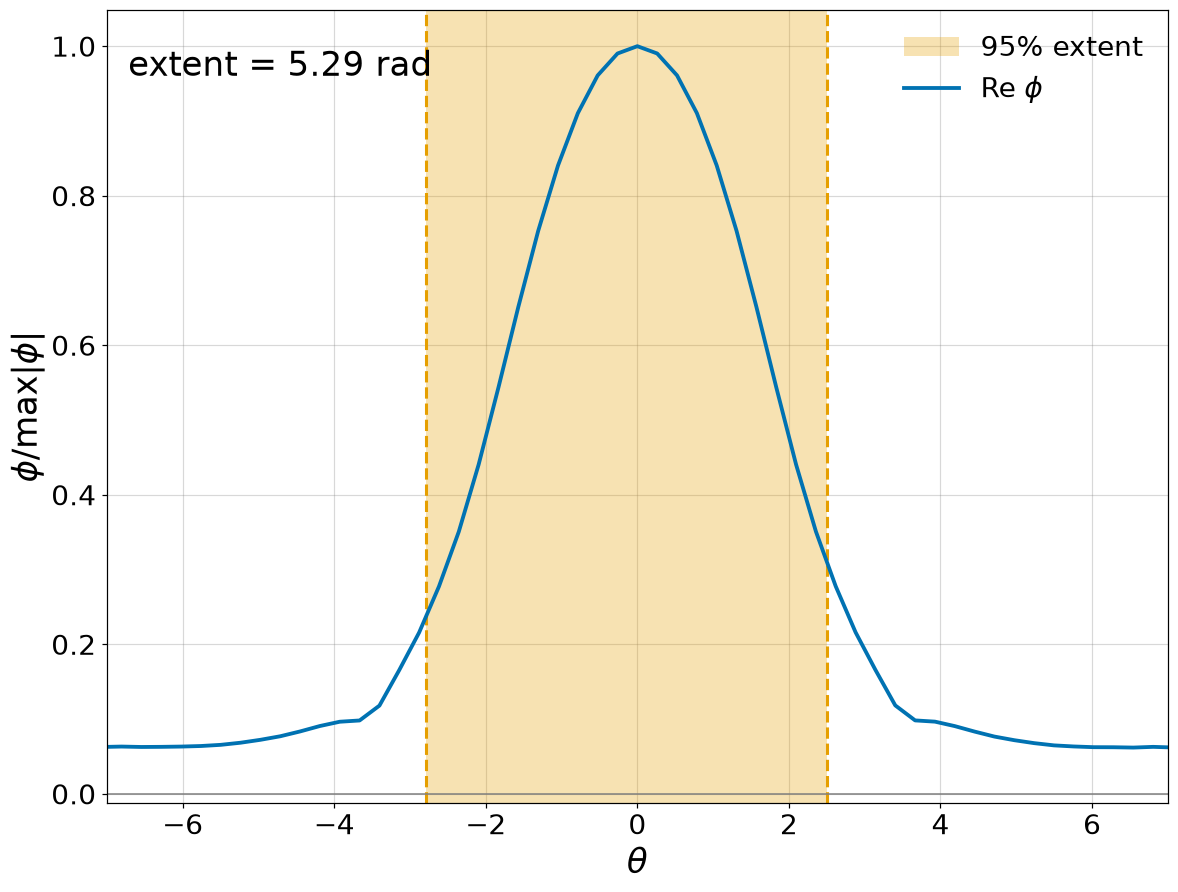

In [3]:
fig, ax_mode = plt.subplots()
ax_mode.axvspan(theta_lo, theta_hi, color="#E69F00", alpha=0.3, lw=0, label="95% extent")
for bound in (theta_lo, theta_hi):
    ax_mode.axvline(bound, color="#E69F00", ls="--", lw=2)
ax_mode.plot(theta, phi_values.real, color="#0072B2", label=r"Re $\phi$")
ax_mode.axhline(0, color="grey", lw=1)
ax_mode.set(xlabel=r"$\theta$", ylabel=r"$\phi / \max|\phi|$", xlim=(-7, 7))
ax_mode.legend(loc="upper right")
ax_mode.text(0.02, 0.95, f"extent = {extent:.2f} rad", transform=ax_mode.transAxes, va="top", fontsize=22)
fig.savefig(plots_dir / "fig_slide_extent_definition.png")
plt.show()